# 03 · Candidate generation, labels and features (steps 2 + 3)

**Input:** cleaned trips in `data/processed/` (from `scripts/run_cleaning.py`).
**Output:** `data/features/<partition>.parquet` (one row per GPS fix × candidate arc) and
`data/features/<partition>_fixes.parquet` (one row per fix), plus `outputs/features/` (report, summary CSV, figures).

The reusable functions live in `src/pathsnap/features.py`, because the FastAPI backend has to run the exact same
candidate + feature code at inference time. This notebook runs them, explains each stage and shows the evidence.

Three stages:
1. **Candidates** (label-free): for each fix, the road arcs that could plausibly be the true one.
2. **Reference labels** (uses `.route`, training/scoring only): which arc each fix was actually on.
3. **Features** (label-free): numbers describing how well each candidate fits its fix.

In [1]:
import sys, time
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from pathsnap import features as F
from pathsnap.cleaning import PROCESSED_ROOT, load_clean_trip

FEAT_ROOT = ROOT / "data" / "features"
OUT = ROOT / "outputs" / "features"
FIG = OUT / "figures"
for d in (FEAT_ROOT, OUT, FIG):
    d.mkdir(parents=True, exist_ok=True)

# chart colours (one fixed order): candidate is the true arc / is not
C_POS, C_NEG, C_GPS, C_GRID = "#2a78d6", "#eb6834", "#1baf7a", "#d9d8d2"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": C_GRID, "grid.linewidth": 0.6, "figure.dpi": 110})

## Parameters

All hand-set from the EDA (`docs/DATA_QUALITY_NOTES.md`), **not** tuned on student-test or evaluator data.

* `CAND_RADIUS_M = 100`: GPS-to-road distance has median 5 m and p95 81 m (the p95 is inflated by parked trips).
* `MAX_CANDS = 16`: about 8 roads, because a two-way road is two arcs.
* `HEADING_HALF_WIN = 2`: heading is taken from the displacement between fix i-2 and i+2. A single 1 s step is too noisy.
* `CONTEXT_HALF_WIN = 5`: features look at the 5 fixes on each side.
* `ALIGN_RADIUS_M = 100`, `ALIGN_BACK_PENALTY_M = 300`: used only for label alignment (see below).

In [2]:
pd.Series({k: getattr(F, k) for k in ["CAND_RADIUS_M", "MAX_CANDS", "HEADING_HALF_WIN", "CONTEXT_HALF_WIN",
                                     "ALIGN_RADIUS_M", "ALIGN_BACK_PENALTY_M"]}, name="value").to_frame()

,value
CAND_RADIUS_M,100.0
MAX_CANDS,16.0
HEADING_HALF_WIN,2.0
CONTEXT_HALF_WIN,5.0
ALIGN_RADIUS_M,100.0
ALIGN_BACK_PENALTY_M,300.0


## Walk-through on one trip (train 00000013)

### Stage 1: candidates
Arcs are straight node-to-node segments in per-trip UTM metres. An STRtree (spatial index) finds every arc within
100 m of each fix. Zero-length arcs and geometric duplicates (`is_duplicate` from cleaning) are left out, since no GPS
fix can tell identical copies apart. If a fix has no arc within 100 m, it gets its single nearest arc
(`is_fallback`), so that every fix still gets a prediction.

In [3]:
c = load_clean_trip("train", "00000013")
cand = F.generate_candidates(c["track"], c["nodes"], c["arcs"])
print(f"{len(c['track'])} fixes, {len(c['arcs'])} arcs in the extract -> {len(cand)} candidate rows "
      f"({len(cand)/len(c['track']):.1f} per fix)")
cand.head()

2580 fixes, 307392 arcs in the extract -> 31555 candidate rows (12.2 per fix)


,fix_idx,arc_id,dist_m,proj_t,off_end_m,is_fallback
0,0,7254,2.993666,0.045596,0.000000,False
1,0,7257,2.993666,0.954404,0.000000,False
2,0,7252,3.864829,1.000000,2.646012,False
3,0,7255,3.864829,0.000000,2.646012,False
4,0,12813,35.818632,1.000000,35.327190,False


### Stage 2: reference label for each fix
`.route` is the ordered list of arcs the car drove. It says nothing about **which fix** was on which arc. The naive rule
"label = nearest route arc" breaks on U-turns and revisited arcs, because the same road appears twice, in each direction.

Instead we **align** the fixes to route positions with dynamic programming:
* the state of fix *i* is a route position *k_i* (only positions within 100 m are considered);
* the cost is the distance from the fix to route arc *k_i*;
* moving forward along the route is free; moving backward costs 300 m, which lets the alignment survive the
  14 known route breaks without making backward moves cheap;
* the minimum-total-cost path is recovered by backtracking (a Viterbi on the route).

Because positions only go forward, the alignment matches the first time the car passes a road with the first time that
road appears in the route, and the second pass with the second. Label = canonical arc at the aligned position. Fixes
with no route arc within 100 m get no label (`true_arc = -1`).

In [4]:
true_arc = F.align_labels(c["track"], c["nodes"], c["arcs"], c["route"])
print(f"labelled fixes: {(true_arc >= 0).mean():.1%}")
print(f"distinct route arcs used by the alignment: {len(set(true_arc[true_arc >= 0]))} of {c['route']['canonical_arc_id'].nunique()}")

labelled fixes: 100.0%
distinct route arcs used by the alignment: 705 of 788


### Stage 3: features
For every (fix, candidate) row, using no route information:

| group | features | why |
|---|---|---|
| geometry | `dist_m`, `dist_rank`, `dist_minus_min`, `dist_ratio`, `n_cands`, `is_fallback`, `proj_t`, `off_end_m`, `arc_length_m` | the closer arc is usually right; rank and gap to the best candidate make the distance relative to the other candidates of that fix |
| direction | `heading_diff_deg`, `heading_cos`, `heading_disp_m` | a two-way road gives **two arcs at the same distance**, so only heading separates them. `heading_disp_m` tells the model when the heading is unreliable (stopped car) |
| temporal consistency | `d_prev_m`, `d_next_m`, `d_win_mean_m`, `d_win_max_m`, `win_mean_rank`, `win_mean_minus_min` | the true arc stays close for several fixes in a row; a parallel road that one noisy fix drifts onto does not |
| motion | `speed_med_mps`, `dt_prev_s`, `is_stop`, `is_fast_step` | median speed is robust to the fast-step runs found in the EDA; when the car is stopped, distance and heading mean less |
| topology | `is_two_way`, `from_in_deg`, `to_out_deg`, `in_largest_scc` | intersections and one-way roads behave differently |

The context windows never cross a GPS gap segment (`segment_id`). Absolute coordinates, timestamps and ids are **not** features.

In [5]:
rows, fixes = F.build_trip_features(c)
rows[["fix_idx", "arc_id", "label"] + F.FEATURE_COLS].head(8)

,fix_idx,arc_id,label,dist_m,dist_rank,dist_minus_min,dist_ratio,n_cands,is_fallback,proj_t,...,win_mean_rank,win_mean_minus_min,speed_med_mps,dt_prev_s,is_stop,is_fast_step,is_two_way,from_in_deg,to_out_deg,in_largest_scc
0,0,7254,1,2.993666,0,0.000000,1.000000,16,False,0.045596,...,0,0.000000,3.022377,1.0,False,False,True,2,2,True
1,0,7257,0,2.993666,1,0.000000,1.000000,16,False,0.954404,...,1,0.000000,3.022377,1.0,False,False,True,2,2,True
2,0,7252,0,3.864829,2,0.871163,1.218136,16,False,1.000000,...,2,4.837045,3.022377,1.0,False,False,True,2,2,True
3,0,7255,0,3.864829,3,0.871163,1.218136,16,False,0.000000,...,3,4.837045,3.022377,1.0,False,False,True,2,2,True
4,0,12813,0,35.818632,4,32.824965,9.219256,16,False,1.000000,...,4,35.549546,3.022377,1.0,False,False,True,2,1,True
5,0,12826,0,35.818632,5,32.824965,9.219256,16,False,0.000000,...,5,35.549546,3.022377,1.0,False,False,True,1,2,True
6,0,7256,0,51.252364,6,48.258698,13.083808,16,False,0.000000,...,6,45.252103,3.022377,1.0,False,False,True,2,2,True
7,0,7259,0,51.252364,7,48.258698,13.083808,16,False,1.000000,...,7,45.252103,3.022377,1.0,False,False,True,2,2,True


### What it looks like: 40 fixes, their candidates and the labelled arc

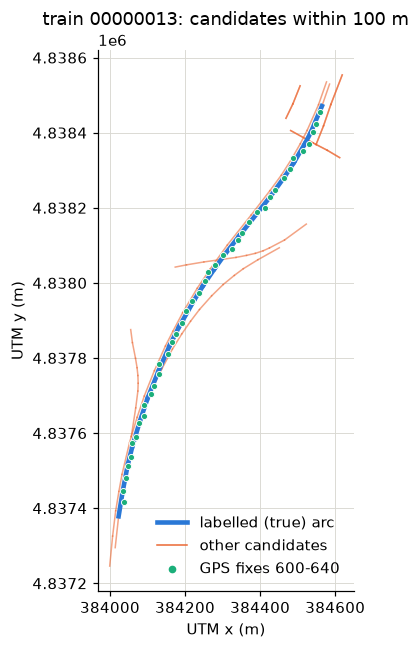

In [6]:
nxy = c["nodes"][["x", "y"]].to_numpy()
fr, to = c["arcs"]["from_node"].to_numpy(), c["arcs"]["to_node"].to_numpy()
win = rows[rows.fix_idx.between(600, 640)]
tr = c["track"].iloc[600:641]
fig, ax = plt.subplots(figsize=(7, 6))
for a in win.loc[win.label == 0, "arc_id"].unique():
    ax.plot(*nxy[[fr[a], to[a]]].T, color=C_NEG, lw=1, alpha=0.6)
for a in win.loc[win.label == 1, "arc_id"].unique():
    ax.plot(*nxy[[fr[a], to[a]]].T, color=C_POS, lw=3)
ax.scatter(tr.x, tr.y, s=16, color=C_GPS, zorder=3, edgecolor="white", linewidth=0.6)
ax.plot([], [], color=C_POS, lw=3, label="labelled (true) arc")
ax.plot([], [], color=C_NEG, lw=1, label="other candidates")
ax.scatter([], [], s=16, color=C_GPS, label="GPS fixes 600-640")
ax.set_aspect("equal"); ax.set_xlabel("UTM x (m)"); ax.set_ylabel("UTM y (m)")
ax.set_title("train 00000013: candidates within 100 m"); ax.legend(loc="best", frameon=False)
fig.tight_layout(); fig.savefig(FIG / "01_candidates_example.png"); plt.show()

## Run every trip (train + student_test)
The trips are independent, so they run in parallel (about 20 s). The evaluator-test partition is not on disk and is never touched.

In [7]:
jobs = [(p, t.name) for p in ("train", "student_test") for t in sorted((PROCESSED_ROOT / p).iterdir())]
t0 = time.perf_counter()
res = {"train": ([], []), "student_test": ([], [])}
summ = []
with ProcessPoolExecutor() as ex:
    for part, r, f, s in ex.map(F.process_trip, jobs):
        res[part][0].append(r); res[part][1].append(f); summ.append(s)
rows_all = {p: pd.concat(r, ignore_index=True) for p, (r, _) in res.items()}
fixes_all = {p: pd.concat(f, ignore_index=True) for p, (_, f) in res.items()}
for p in rows_all:
    rows_all[p].to_parquet(FEAT_ROOT / f"{p}.parquet", index=False)
    fixes_all[p].to_parquet(FEAT_ROOT / f"{p}_fixes.parquet", index=False)
summary = pd.DataFrame(summ)
summary.to_csv(OUT / "feature_summary.csv", index=False)
print(f"{len(jobs)} trips in {time.perf_counter() - t0:.0f} s")

90 trips in 15 s


## Candidate quality
**Candidate miss rate** = share of label-reliable fixes whose reference arc is **not** in the candidate set. Nothing
downstream can recover those fixes, so this rate caps the achievable accuracy. **Nearest-arc Top-1** is the no-model
baseline that always picks the closest candidate.

In [8]:
tab = []
for p in rows_all:
    r, f = rows_all[p], fixes_all[p]
    rel = f[f.label_reliable]
    tab.append({"partition": p, "trips": f.trip_id.nunique(), "fixes": len(f), "candidate rows": len(r),
                "mean cands/fix": round(len(r) / len(f), 1), "positive rate": round(r.label.mean(), 4),
                "reliable fixes": len(rel), "miss rate": round(1 - rel.true_in_cands.mean(), 4),
                "nearest-arc Top-1": round(rel.nearest_is_true.mean(), 4)})
part_tab = pd.DataFrame(tab).set_index("partition")
part_tab

,trips,fixes,candidate rows,mean cands/fix,positive rate,reliable fixes,miss rate,nearest-arc Top-1
partition,,,,,,,,
train,80,208417,2261830,10.9,0.0826,180978,0.0010,0.5540
student_test,10,19160,231918,12.1,0.0826,19133,0.0003,0.5125


In [9]:
worst = summary.sort_values("miss_rate_reliable", ascending=False).head(8)
worst[["partition", "trip_id", "n_fixes", "frac_reliable", "miss_rate_reliable", "nearest_acc_reliable"]]

,partition,trip_id,n_fixes,frac_reliable,miss_rate_reliable,nearest_acc_reliable
58,train,00000072,969,1.000000,0.092879,0.341589
49,train,00000061,1430,0.995105,0.040056,0.272663
74,train,00000093,1211,0.993394,0.020781,0.543641
3,train,00000004,1064,1.000000,0.001880,0.445489
72,train,00000090,536,1.000000,0.001866,0.559701
47,train,00000058,599,1.000000,0.001669,0.572621
55,train,00000069,2067,1.000000,0.001451,0.474117
87,student_test,00000076,1486,1.000000,0.001346,0.390983


Only three trips (72, 61, 93) have a miss rate above 1 %. Everywhere else the 100 m / 16-candidate set contains the
true arc for practically every fix, so a larger radius would only add negatives.

## Do the features separate true from wrong candidates?
These are training rows only (`label_reliable & ~exclude_trip`), so trips 33 and 54 and the far-from-route fixes are left out.

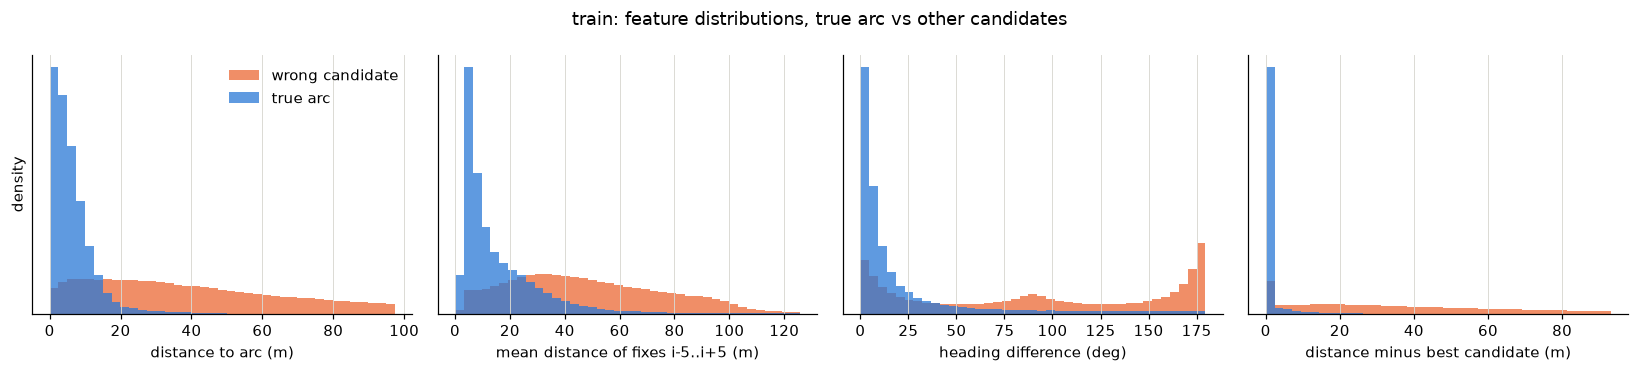

In [10]:
tr_rows = rows_all["train"]
tr_rows = tr_rows[tr_rows.label_reliable & ~tr_rows.exclude_trip]
show = [("dist_m", "distance to arc (m)"), ("d_win_mean_m", "mean distance of fixes i-5..i+5 (m)"),
        ("heading_diff_deg", "heading difference (deg)"), ("dist_minus_min", "distance minus best candidate (m)")]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (col, lab) in zip(axes, show):
    bins = np.linspace(0, tr_rows[col].quantile(0.99), 40)
    ax.hist(tr_rows.loc[tr_rows.label == 0, col], bins=bins, density=True, color=C_NEG, alpha=0.75, label="wrong candidate")
    ax.hist(tr_rows.loc[tr_rows.label == 1, col], bins=bins, density=True, color=C_POS, alpha=0.75, label="true arc")
    ax.set_xlabel(lab); ax.set_yticks([])
axes[0].set_ylabel("density"); axes[0].legend(frameon=False)
fig.suptitle("train: feature distributions, true arc vs other candidates")
fig.tight_layout(); fig.savefig(FIG / "02_feature_separation.png"); plt.show()

The heading plot is bimodal for wrong candidates: the peak near 180° is the opposite-direction arc of the same road.
Distance cannot separate that arc from the true one, but heading can.

### Sanity baseline (not a model)
A quick hand-written score, `d_win_mean_m + 20·(1 − heading_cos)` (heading ignored when the car barely moved),
checks that the features carry signal before step 4. Nothing here is fitted.

In [11]:
base = []
for p, r in rows_all.items():
    r = r[r.label_reliable & ~r.exclude_trip].copy()
    r["score"] = r.d_win_mean_m + 20 * (1 - r.heading_cos) * (r.heading_disp_m > 5)
    near = r[r.dist_rank == 0]
    rule = r.loc[r.groupby(["trip_id", "fix_idx"]).score.idxmin()]
    base.append({"partition": p, "nearest-arc Top-1": round(near.label.mean(), 4),
                 "hand rule Top-1": round(rule.label.mean(), 4)})
base = pd.DataFrame(base).set_index("partition")
base

,nearest-arc Top-1,hand rule Top-1
partition,,
train,0.5540,0.8018
student_test,0.5125,0.7937


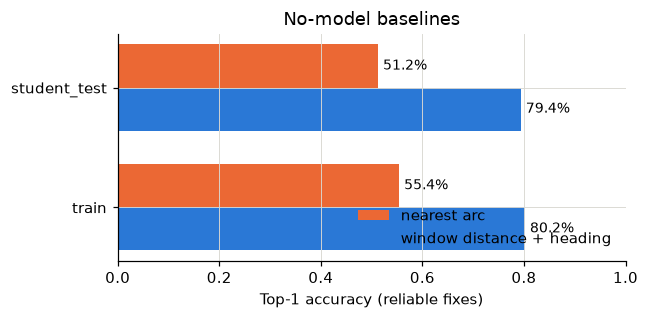

In [12]:
fig, ax = plt.subplots(figsize=(6, 3))
y = np.arange(len(base)); h = 0.36
ax.barh(y + h / 2, base["nearest-arc Top-1"], h, color=C_NEG, label="nearest arc")
ax.barh(y - h / 2, base["hand rule Top-1"], h, color=C_POS, label="window distance + heading")
for yy, v in zip(y + h / 2, base["nearest-arc Top-1"]): ax.text(v + 0.01, yy, f"{v:.1%}", va="center", fontsize=9)
for yy, v in zip(y - h / 2, base["hand rule Top-1"]): ax.text(v + 0.01, yy, f"{v:.1%}", va="center", fontsize=9)
ax.set_yticks(y, base.index); ax.set_xlim(0, 1); ax.set_xlabel("Top-1 accuracy (reliable fixes)")
ax.legend(frameon=False, loc="lower right"); ax.set_title("No-model baselines")
fig.tight_layout(); fig.savefig(FIG / "03_baselines.png"); plt.show()

## Save the report

In [13]:
L = ["# PathSnap: Candidates, Labels and Features",
     "", "Auto-generated by `notebooks/03_features.ipynb`.", "", "## Parameters (hand-set)", "",
     pd.Series({k: getattr(F, k) for k in ["CAND_RADIUS_M", "MAX_CANDS", "HEADING_HALF_WIN", "CONTEXT_HALF_WIN",
                "ALIGN_RADIUS_M", "ALIGN_BACK_PENALTY_M"]}, name="value").to_markdown(),
     "", "## Per partition", "", part_tab.to_markdown(), "",
     "## No-model baselines (reliable fixes)", "", base.to_markdown(), "",
     "## Highest candidate miss rates", "",
     worst[["partition", "trip_id", "n_fixes", "frac_reliable", "miss_rate_reliable", "nearest_acc_reliable"]].to_markdown(index=False),
     "", "## Columns", "",
     f"* Keys: `{', '.join(F.KEY_COLS)}`. `trip_id` is the group for GroupKFold.",
     f"* Model inputs (`FEATURE_COLS`, {len(F.FEATURE_COLS)}): `{', '.join(F.FEATURE_COLS)}`.",
     f"* Route-based, never inputs (`LABEL_COLS`): `{', '.join(F.LABEL_COLS)}`.",
     "* Training rows: `label_reliable & ~exclude_trip`.", "",
     "![candidates](figures/01_candidates_example.png)", "![features](figures/02_feature_separation.png)",
     "![baselines](figures/03_baselines.png)"]
(OUT / "FEATURES_REPORT.md").write_text("\n".join(L) + "\n")
print("wrote", OUT / "FEATURES_REPORT.md")

wrote C:\College\sem-v\ml\ml_hackathon\PATHSNAP\outputs\features\FEATURES_REPORT.md


## Handover to step 4 (model training)
```python
df = pd.read_parquet("data/features/train.parquet")
df = df[df.label_reliable & ~df.exclude_trip]
X, y, groups = df[F.FEATURE_COLS], df["label"], df["trip_id"]   # GroupKFold on trip_id
```
Top-1 = for each `(trip_id, fix_idx)`, pick the highest-scoring candidate and check its `label`.
Never use the columns in `LABEL_COLS` as inputs.